# pyPRB showcase

This notebook shows every balancing method in pyPRB:

1. [Vectors and the angle convention](#1.-Vectors-and-the-angle-convention)
2. [Static (single-plane) balancing](#2.-Static-(single-plane)-balancing) — `StaticBalancing`
3. [Dynamic (two-plane) balancing](#3.-Dynamic-(two-plane)-balancing) — `DynamicBalancing`
4. [Multi-plane balancing](#4.-Multi-plane-balancing) — `MultiPlaneBalancing`
   * the one- and two-plane cases give the same result as `StaticBalancing` and `DynamicBalancing`,
   * three planes on a simulated rotor,
   * more measurement points than planes (least squares).
5. [From time signals to a correction](#5.-From-time-signals-to-a-correction) — `detect_rotation_freq`, `VibrationExtractor` and the four extraction methods.

The worked examples with published results come from the application note *Static and Dynamic Balancing using portable measuring equipment* (J. Vaughan, Brüel & Kjær). The other examples use simulated data, so the correct answer is known.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pyPRB import (
    VibrationVector, MassVector,
    StaticBalancing, DynamicBalancing, MultiPlaneBalancing,
    VibrationExtractor, detect_rotation_freq,
    IQDemodulation, LeastSquaresFit, SynchronousAveraging, FFTExtraction,
)


def plot_vectors(ax, vectors, labels, title=None):
    # Draw vibration vectors (VibrationVector or complex) on a polar axis.
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for k, (v, label) in enumerate(zip(vectors, labels)):
        z = v.complex_num if isinstance(v, VibrationVector) else complex(v)
        ax.annotate("", xy=(np.angle(z), abs(z)), xytext=(0, 0),
                    arrowprops=dict(arrowstyle="->", lw=2,
                                    color=colors[k % len(colors)]))
        ax.plot([], [], color=colors[k % len(colors)], lw=2, label=label)
    rmax = max(abs(v.complex_num if isinstance(v, VibrationVector) else v)
               for v in vectors)
    ax.set_rmax(1.15 * rmax)
    ax.legend(loc="upper left", bbox_to_anchor=(1.05, 1.0), fontsize=9)
    if title:
        ax.set_title(title, pad=15)

## 1. Vectors and the angle convention

All angles are measured from the trigger/datum mark on the rotor, positive in the direction of rotation.

* `VibrationVector(amplitude, phase)` is the once-per-revolution (1×) vibration; internally it is a complex number and supports `+`, `-`, `*` and `/`.
* `MassVector(amplitude, phase, units="g")` is a mass mounted at an angular position on the rotor. Its phase is reported in the range (−180°, 180°].

In [2]:
v1 = VibrationVector(10.0, 45)
v2 = VibrationVector(5.0, 135)
print("v1 + v2 =", v1 + v2)
print("v1 - v2 =", v1 - v2)
print("v1 / v2 =", v1 / v2)
print("-v1     =", -v1)
print(MassVector(2.5, 300, units="g"))

v1 + v2 = VibrationVector(amplitude=11.1803, phase=71.5651°)
v1 - v2 = VibrationVector(amplitude=11.1803, phase=18.4349°)
v1 / v2 = VibrationVector(amplitude=2, phase=270°)
-v1     = VibrationVector(amplitude=10, phase=225°)
MassVector(amplitude=2.5, phase=-60°, units='g')


## 2. Static (single-plane) balancing

For a narrow rotor (a disc, a fan, a grindstone) one correction plane is enough. Two runs are needed:

* run 0: the rotor as it is, vibration $V_0$,
* run 1: with a trial mass $T$, vibration $V_1$.

The effect of the trial mass is $V_T = V_1 - V_0$. The compensation mass cancels $V_0$: it is $T\,|V_0|/|V_T|$, mounted at the angle that turns $V_T$ opposite to $V_0$.

B&K example: $V_0 = 3.4$ @ 116°, $V_1 = 1.8$ @ 42°, trial mass 2.0 g @ 0°. The application note gives 2.0 g at −31° (329°).

In [3]:
V_0 = VibrationVector(3.4, 116)
V_1 = VibrationVector(1.8, 42)
trial_mass = MassVector(2.0, 0.0)

static = StaticBalancing(V_0, V_1, trial_mass=trial_mass)
print(static)
comp_static = static.compute_compensation()


Static Balancing - Measured Vibration Data
+--------------+-------------+---------+----------+
|  Trial Mass  |  Amplitude  |  Phase  |  Vector  |
+==============+=============+=========+==========+
|     None     |     3.4     |  116°   |   V_0    |
+--------------+-------------+---------+----------+
|  2.0 g @ 0°  |     1.8     |   42°   |   V_1    |
+--------------+-------------+---------+----------+
Compensation mass: 2.01 g at position -30.8° on the rotor.


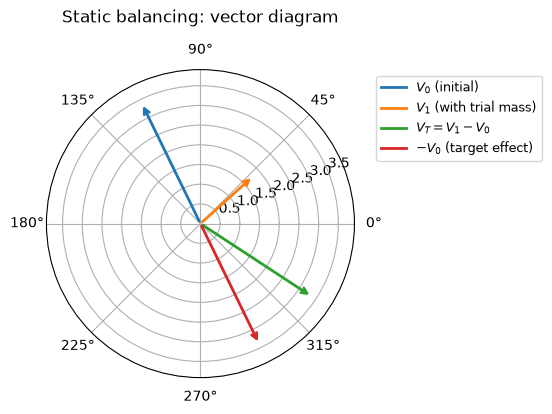

In [4]:
V_T = V_1 - V_0
fig, ax = plt.subplots(subplot_kw={"projection": "polar"}, figsize=(5, 4))
plot_vectors(ax, [V_0, V_1, V_T, -V_0],
             ["$V_0$ (initial)", "$V_1$ (with trial mass)",
              "$V_T = V_1 - V_0$", "$-V_0$ (target effect)"],
             "Static balancing: vector diagram")
plt.show()

The trial mass does not have to be at the datum. If it is mounted at 25°, the measured vectors are unchanged in this example but the compensation is rotated by the same 25°: positions are always absolute, on the rotor.

In [5]:
StaticBalancing(V_0, V_1, trial_mass=MassVector(2.0, 25.0)).compute_compensation();

Compensation mass: 2.01 g at position -5.8° on the rotor.


## 3. Dynamic (two-plane) balancing

A long rotor needs two correction planes and vibration measured at two points (usually the bearings). Three runs are needed: the initial run, a run with a trial mass in plane 1 and a run with a trial mass in plane 2. `V_i_j` is the vibration at point *i* in run *j*.

B&K example 4; the application note gives 2.93 g @ 50.4° in plane 1 and 2.84 g @ −81.9° in plane 2.

In [6]:
V_1_0, V_2_0 = VibrationVector(7.2, 238), VibrationVector(13.5, 296)   # initial run
V_1_1, V_2_1 = VibrationVector(4.9, 114), VibrationVector(9.2, 347)    # trial mass in plane 1
V_1_2, V_2_2 = VibrationVector(4.0, 79),  VibrationVector(12.0, 292)   # trial mass in plane 2
trial_mass_1 = MassVector(2.5, 0.0)
trial_mass_2 = MassVector(2.5, 0.0)

dynamic = DynamicBalancing(V_1_0, V_2_0, V_1_1, V_2_1, V_1_2, V_2_2,
                           trial_mass_1=trial_mass_1, trial_mass_2=trial_mass_2)
print(dynamic)
comp_dynamic = dynamic.compute_compensation()


Dynamic Balancing - Measured Vibration Data
+-----------------------+-------------+-------------+----------+-------------+-------------+----------+
|      Trial Mass       |  Amplitude  |    Phase    |  Vector  |  Amplitude  |    Phase    |  Vector  |
|   Size and Location   |  (Plane 1)  |  (Plane 1)  |          |  (Plane 2)  |  (Plane 2)  |          |
+=======================+=============+=============+==========+=============+=============+==========+
|         None          |     7.2     |    238°     |  V_1_0   |    13.5     |    296°     |  V_2_0   |
+-----------------------+-------------+-------------+----------+-------------+-------------+----------+
| 2.5 g @ 0° on Plane 1 |     4.9     |    114°     |  V_1_1   |     9.2     |    347°     |  V_2_1   |
+-----------------------+-------------+-------------+----------+-------------+-------------+----------+
| 2.5 g @ 0° on Plane 2 |      4      |     79°     |  V_1_2   |     12      |    292°     |  V_2_2   |
+------------------

## 4. Multi-plane balancing

`MultiPlaneBalancing` uses the influence coefficient method for any number of correction planes $N$ and measurement points $M \ge N$. Run $j$ adds a trial mass $T_j$ to plane $j$; vibration is measured at all $M$ points in every run.

The influence coefficient of plane $j$ on point $i$ is

$$\alpha_{ij} = \frac{V_{ij} - V_{i0}}{T_j},$$

and the compensation masses $\mathbf W$ follow from $\boldsymbol\alpha\,\mathbf W = -\mathbf V_0$. For $M = N$ the system is solved exactly, for $M > N$ in the least-squares sense.

The input is

* `V_0`: list of $M$ vectors (initial run),
* `V_trial`: list of $N$ runs, `V_trial[j][i]` = point $i$ with the trial mass in plane $j$,
* `trial_masses`: list of $N$ `MassVector`.

### 4.1 Same result as the static and dynamic classes

With one plane and one point it is static balancing; with two planes and two points it is dynamic balancing.

In [7]:
(comp_mp_static,) = MultiPlaneBalancing(
    [V_0], [[V_1]], [trial_mass]).compute_compensation(repr=False)

comp_mp_dynamic = MultiPlaneBalancing(
    V_0=[V_1_0, V_2_0],
    V_trial=[[V_1_1, V_2_1],    # trial mass in plane 1
             [V_1_2, V_2_2]],   # trial mass in plane 2
    trial_masses=[trial_mass_1, trial_mass_2],
).compute_compensation(repr=False)

print("Static : StaticBalancing     ", comp_static)
print("         MultiPlaneBalancing ", comp_mp_static)
print("Dynamic: DynamicBalancing    ", comp_dynamic[0], comp_dynamic[1])
print("         MultiPlaneBalancing ", comp_mp_dynamic[0], comp_mp_dynamic[1])

Static : StaticBalancing      MassVector(amplitude=2.01168, phase=-30.7888°, units='g')
         MultiPlaneBalancing  MassVector(amplitude=2.01168, phase=-30.7888°, units='g')
Dynamic: DynamicBalancing     MassVector(amplitude=2.95138, phase=50.1889°, units='g') MassVector(amplitude=2.84414, phase=-81.8841°, units='g')
         MultiPlaneBalancing  MassVector(amplitude=2.95138, phase=50.1889°, units='g') MassVector(amplitude=2.84414, phase=-81.8841°, units='g')


### 4.2 Three correction planes

A simulated rotor with three correction planes and three measurement points. The rotor is linear: the vibration is $\mathbf V = \boldsymbol\alpha\,(\mathbf U + \text{masses added})$, where $\mathbf U$ is the unknown initial unbalance. We generate the four runs, give them to `MultiPlaneBalancing` and check that the compensation is $-\mathbf U$.

In [8]:
rng = np.random.default_rng(3)

def as_complex(mass):
    return mass.amplitude * np.exp(1j * np.deg2rad(mass.phase))

def simulate_runs(alpha, unbalance, trial_masses, noise=0.0, rng=None):
    # Initial run and one trial run per plane for a linear rotor model.
    def measure(z):
        if noise:
            z = z + noise * (rng.standard_normal(z.shape)
                             + 1j * rng.standard_normal(z.shape))
        return [VibrationVector.from_complex(v) for v in z]
    V_0 = measure(alpha @ unbalance)
    V_trial = []
    for j, tm in enumerate(trial_masses):
        added = np.zeros(len(trial_masses), dtype=complex)
        added[j] = as_complex(tm)
        V_trial.append(measure(alpha @ (unbalance + added)))
    return V_0, V_trial

# Influence coefficients (vibration per gram at 0°), unknown to the balancer
alpha_3 = np.array([[1.0 * np.exp(0.3j), 0.4 * np.exp(1.2j), 0.1 * np.exp(2.0j)],
                    [0.5 * np.exp(-0.4j), 1.2 * np.exp(0.1j), 0.5 * np.exp(0.9j)],
                    [0.1 * np.exp(1.5j), 0.3 * np.exp(-0.6j), 0.9 * np.exp(0.5j)]])
# Initial unbalance in g at its angle
U_3 = np.array([3.0 * np.exp(np.deg2rad(40) * 1j),
                1.5 * np.exp(np.deg2rad(200) * 1j),
                2.2 * np.exp(np.deg2rad(-75) * 1j)])
trial_masses_3 = [MassVector(2.0, 0.0), MassVector(2.0, 0.0), MassVector(2.0, 90.0)]

V_0_3, V_trial_3 = simulate_runs(alpha_3, U_3, trial_masses_3)
mp3 = MultiPlaneBalancing(V_0_3, V_trial_3, trial_masses_3)
print(mp3)
comp_3 = mp3.compute_compensation()


Multi-Plane Balancing - Measured Vibration Data
+----------------------+--------------------+---------------------+---------------------+
|      Trial Mass      |     Vibration      |      Vibration      |      Vibration      |
|  Size and Location   |     (Point 1)      |      (Point 2)      |      (Point 3)      |
+======================+====================+=====================+=====================+
|         None         | 2.72519 @ 49.1605° |  1.13168 @ 316.55°  | 1.31597 @ 304.991°  |
+----------------------+--------------------+---------------------+---------------------+
| 2 g @ 0° on Plane 1  | 4.54685 @ 35.6921° | 2.09768 @ 326.175°  | 1.16747 @ 311.186°  |
+----------------------+--------------------+---------------------+---------------------+
| 2 g @ 0° on Plane 2  | 3.48919 @ 53.5704° | 3.25447 @ 350.473°  | 1.88936 @ 311.416°  |
+----------------------+--------------------+---------------------+---------------------+
| 2 g @ 90° on Plane 3 | 2.54466 @ 51.0333° | 0.161

In [9]:
print("Expected compensation (-U):")
for j, u in enumerate(-U_3, start=1):
    print(f"  plane {j}: {abs(u):.3f} g at {np.rad2deg(np.angle(u)):.1f}°")
print("\nIdentified influence coefficients equal the model:",
      np.allclose(mp3.influence_coefficients, alpha_3))
print("Predicted residual vibration:",
      [f"{v.amplitude:.1e}" for v in mp3.residual_vibration()])

Expected compensation (-U):
  plane 1: 3.000 g at -140.0°
  plane 2: 1.500 g at 20.0°
  plane 3: 2.200 g at 105.0°

Identified influence coefficients equal the model: True
Predicted residual vibration: ['6.3e-16', '4.0e-16', '1.3e-15']


### 4.3 More measurement points than planes (least squares)

Often there are more sensors than correction planes, for example horizontal and vertical sensors on each bearing. Then the masses cannot cancel the vibration at every point; `MultiPlaneBalancing` returns the masses that minimise the sum of squared residual amplitudes, and `residual_vibration()` predicts what remains.

Below: 3 correction planes, 6 measurement points, and measurement noise.

+---------+---------------------+------------+
|  Plane  |  Compensation Mass  |  Position  |
+=========+=====================+============+
|    1    |       3.00 g        |  -137.9°   |
+---------+---------------------+------------+
|    2    |       1.51 g        |   16.6°    |
+---------+---------------------+------------+
|    3    |       2.20 g        |   104.5°   |
+---------+---------------------+------------+


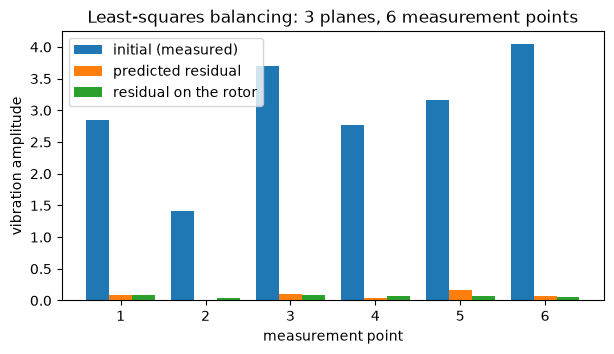

In [10]:
rng = np.random.default_rng(7)
alpha_6 = (rng.uniform(0.2, 1.2, (6, 3))
           * np.exp(1j * rng.uniform(-np.pi, np.pi, (6, 3))))
V_0_6, V_trial_6 = simulate_runs(alpha_6, U_3, trial_masses_3, noise=0.05, rng=rng)

mp6 = MultiPlaneBalancing(V_0_6, V_trial_6, trial_masses_3)
comp_6 = mp6.compute_compensation()
residual_6 = mp6.residual_vibration()

# What actually remains on the (simulated) rotor after fitting the masses
W_6 = np.array([as_complex(m) for m in comp_6])
actual_6 = np.abs(alpha_6 @ (U_3 + W_6))

points = np.arange(1, 7)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(points - 0.27, [v.amplitude for v in V_0_6], 0.27, label="initial (measured)")
ax.bar(points, [v.amplitude for v in residual_6], 0.27, label="predicted residual")
ax.bar(points + 0.27, actual_6, 0.27, label="residual on the rotor")
ax.set_xlabel("measurement point")
ax.set_ylabel("vibration amplitude")
ax.set_xticks(points)
ax.legend()
ax.set_title("Least-squares balancing: 3 planes, 6 measurement points")
plt.show()

## 5. From time signals to a correction

In the field the vectors come from a vibration signal and a once-per-revolution trigger (a tachometer or an optical probe on a reflective mark). The steps are:

1. `detect_rotation_freq` finds the rotation frequency from the trigger,
2. `VibrationExtractor(...).get_vibration_vector(signal, trigger)` extracts the 1× amplitude and phase relative to the trigger.

Four extraction methods can be selected with `method=`:

| method | idea |
|---|---|
| `IQDemodulation` (default) | correlation with cosine and sine at the rotation frequency (lock-in) |
| `LeastSquaresFit` | least-squares fit of a sine, best under Gaussian noise |
| `SynchronousAveraging` | averaging of revolutions between trigger crossings |
| `FFTExtraction` | phase of the 1× FFT line minus the trigger phase |

### 5.1 Static balancing from signals, with all four methods

Simulated signals of the B&K static example (25 Hz, 5 s, with noise and a 2× component).

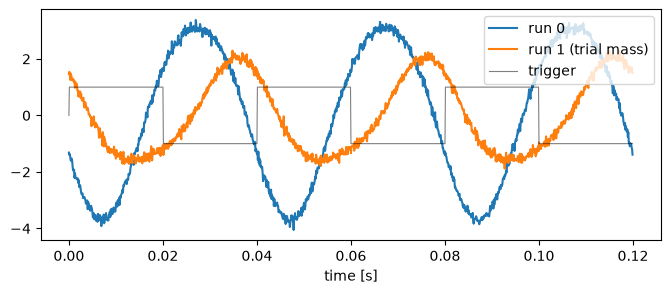

Detected rotation frequency: 25.000 Hz


In [11]:
sample_rate = 10_000   # Hz
f_rot = 25.0           # Hz
t = np.arange(0, 5.0, 1 / sample_rate)
rng = np.random.default_rng(0)

trigger = np.sign(np.sin(2 * np.pi * f_rot * t))

def vibration_signal(v, noise=0.1):
    # 1x component with the amplitude and phase of v, plus 2x and noise.
    x = v.amplitude * np.cos(2 * np.pi * f_rot * t + np.deg2rad(v.phase))
    x += 0.3 * np.cos(2 * 2 * np.pi * f_rot * t + 1.0)
    return x + noise * rng.standard_normal(len(t))

signal_0 = vibration_signal(V_0)
signal_1 = vibration_signal(V_1)

fig, ax = plt.subplots(figsize=(8, 3))
n = int(0.12 * sample_rate)
ax.plot(t[:n], signal_0[:n], label="run 0")
ax.plot(t[:n], signal_1[:n], label="run 1 (trial mass)")
ax.plot(t[:n], trigger[:n], "k", lw=0.8, alpha=0.5, label="trigger")
ax.set_xlabel("time [s]")
ax.legend(loc="upper right")
plt.show()

f_detected = detect_rotation_freq(trigger, sample_rate=sample_rate, max_freq=50.0)
print(f"Detected rotation frequency: {f_detected:.3f} Hz")

In [12]:
methods = {
    "IQDemodulation": IQDemodulation(),
    "LeastSquaresFit": LeastSquaresFit(),
    "SynchronousAveraging": SynchronousAveraging(),
    "FFTExtraction": FFTExtraction(),
}
print(f"{'method':<22}{'V_0':>18}{'V_1':>18}   compensation")
for name, method in methods.items():
    extractor = VibrationExtractor(sample_rate=sample_rate,
                                   rotation_freq=f_detected, method=method)
    V_0_m = extractor.get_vibration_vector(signal_0, trigger)
    V_1_m = extractor.get_vibration_vector(signal_1, trigger)
    comp = StaticBalancing(V_0_m, V_1_m, trial_mass=trial_mass
                           ).compute_compensation(repr=False)
    print(f"{name:<22}{V_0_m.amplitude:8.3f} @ {V_0_m.phase:6.1f}°"
          f"{V_1_m.amplitude:8.3f} @ {V_1_m.phase:6.1f}°"
          f"   {comp.amplitude:.3f} g @ {comp.phase:.1f}°")
print(f"{'exact vectors':<22}{V_0.amplitude:8.3f} @ {V_0.phase:6.1f}°"
      f"{V_1.amplitude:8.3f} @ {V_1.phase:6.1f}°"
      f"   {comp_static.amplitude:.3f} g @ {comp_static.phase:.1f}°")

method                               V_0               V_1   compensation
IQDemodulation           3.401 @  205.7°   1.800 @  131.8°   2.012 g @ -30.8°
LeastSquaresFit          3.401 @  205.7°   1.800 @  131.8°   2.012 g @ -30.8°
SynchronousAveraging     3.401 @  115.3°   1.800 @   41.3°   2.012 g @ -30.8°
FFTExtraction            3.401 @  205.7°   1.799 @  131.8°   2.012 g @ -30.8°
exact vectors            3.400 @  116.0°   1.800 @   42.0°   2.012 g @ -30.8°


All four methods give the same compensation. The extracted phases differ by a constant offset: `IQDemodulation`, `LeastSquaresFit` and `FFTExtraction` measure the phase relative to the fundamental of the trigger signal, `SynchronousAveraging` relative to the trigger crossing. With the sine-shaped square-wave trigger used here the two references are 90° apart. Because every run is processed with the same reference, the offset cancels in the balancing calculation; only the vectors from different methods must not be mixed. Issue #10 proposes the trigger edge as the common reference for all methods.

### 5.2 Multi-plane balancing from signals

The three-plane rotor from section 4.2, now measured as time signals at three points in four runs. The extracted vectors go straight into `MultiPlaneBalancing`.

In [13]:
extractor = VibrationExtractor(sample_rate=sample_rate, rotation_freq=f_detected)

def measure_run(vectors):
    # Extract one vector per measurement point from simulated signals.
    return [extractor.get_vibration_vector(vibration_signal(v, noise=0.2), trigger)
            for v in vectors]

V_0_sig = measure_run(V_0_3)
V_trial_sig = [measure_run(run) for run in V_trial_3]

comp_sig = MultiPlaneBalancing(V_0_sig, V_trial_sig, trial_masses_3
                               ).compute_compensation(repr=False)
print(f"{'plane':<7}{'from signals':>22}{'exact':>22}")
for j, (m_sig, m_exact) in enumerate(zip(comp_sig, comp_3), start=1):
    print(f"{j:<7}{m_sig.amplitude:12.3f} g @ {m_sig.phase:6.1f}°"
          f"{m_exact.amplitude:12.3f} g @ {m_exact.phase:6.1f}°")

plane            from signals                 exact
1             3.000 g @ -140.0°       3.000 g @ -140.0°
2             1.502 g @   19.9°       1.500 g @   20.0°
3             2.203 g @  105.0°       2.200 g @  105.0°


## Summary

| situation | class | runs | input |
|---|---|---|---|
| narrow rotor, one plane | `StaticBalancing` | 2 | `V_0`, `V_1`, trial mass |
| long rotor, two planes | `DynamicBalancing` | 3 | `V_1_0 … V_2_2`, two trial masses |
| $N$ planes, $M = N$ points | `MultiPlaneBalancing` | $N + 1$ | `V_0` ($M$), `V_trial` ($N \times M$), $N$ trial masses |
| $N$ planes, $M > N$ points | `MultiPlaneBalancing` (least squares) | $N + 1$ | same; `residual_vibration()` predicts what remains |
| from time signals | `detect_rotation_freq`, `VibrationExtractor` + any of the above | | signal and trigger for each point and run |